# 08 · Análisis complementario: pares de planetas adyacentes

**Lugar en la tesis:** anexo (análisis exploratorio que complementa la sección 6.4). No forma parte de los tres análisis principales.

**Pregunta.** Dentro de un mismo sistema, ¿los planetas vecinos más separados en período son menos parecidos en tamaño? ¿Depende de la estrella?

**Unidad de análisis.** El par de planetas adyacentes (ordenados por período) de los sistemas del análisis III.

**Variables.**
- `log_period_ratio` = $\ln(P_{\rm ext}/P_{\rm int})$: separación orbital del par.
- `abs_log_radius_ratio` = $U_R = |\ln(R_{\rm ext}/R_{\rm int})|$: desigualdad de tamaños (0 = radios iguales).
- `outer_larger` = 1 si el planeta exterior es el mayor.
- `pair_type`: `par_rocoso` (ambos $R_p \leq 1.6\,R_\oplus$), `par_volatil` (ambos $> 1.6$) o `par_mixto`.

Como varios pares comparten estrella, los modelos se reportan con errores estándar agrupados por estrella.

**Salidas:** tablas C-T1 a C-T6; figuras C-F1 a C-F3; `data_processed/06_pares_adyacentes.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from funciones import *

usar_estilo()

## 1. Pares adyacentes

In [2]:
df = cargar_catalogo()
candidatos = pd.read_csv(DATOS_PROCESADOS / "04_planetas_en_sistemas.csv")
sistemas = pd.read_csv(DATOS_PROCESADOS / "05_sistemas_planetarios_enriquecido.csv")
pares = construir_pares(candidatos).merge(sistemas[["hostname", "gapped"]], on="hostname")
pares.to_csv(DATOS_PROCESADOS / "06_pares_adyacentes.csv", index=False)
TIPOS = ["par_rocoso", "par_mixto", "par_volatil"]
ETIQUETA_TIPO = {"par_rocoso": "Rocoso", "par_mixto": "Mixto", "par_volatil": "Volátil"}
print(f"Pares: {len(pares)} en {pares['hostname'].nunique()} sistemas")

descriptiva_global = descriptiva(pares, ["period_ratio", "log_period_ratio", "radius_ratio", "abs_log_radius_ratio"])
por_tipo = resumen_por_grupo(pares, "pair_type", "abs_log_radius_ratio", TIPOS)
por_tipo = por_tipo.rename(columns={"pair_type": "variable"})
por_tipo["variable"] = "abs_log_radius_ratio en " + por_tipo["variable"]
tabla_pares = guardar_tabla(
    pd.concat([descriptiva_global, por_tipo], ignore_index=True), "C-T1", "descripcion_de_pares_adyacentes",
    titulo="Pares de planetas adyacentes: estadística descriptiva de la separación orbital y de la desigualdad de tamaños, global y por tipo de par.",
    seccion="Anexo", destino="anexo",
    nota=f"{len(pares)} pares en {pares['hostname'].nunique()} sistemas. Fracción de pares con el planeta exterior mayor: {pares['outer_larger'].mean():.3f}.")
tabla_pares

Pares: 898 en 615 sistemas
Tabla C-T1 guardada: tablas/C-T1_descripcion_de_pares_adyacentes.csv


,variable,N,mediana,Q1,Q3,IQR,minimo,maximo
0,period_ratio,898,2.1660,1.7204,3.1207,1.4003,1.0383,54.0833
1,log_period_ratio,898,0.7729,0.5426,1.1381,0.5955,0.0376,3.9905
2,radius_ratio,898,1.1501,0.9486,1.4799,0.5313,0.4124,3.6749
3,abs_log_radius_ratio,898,0.2223,0.0953,0.4383,0.3430,0.0000,1.3015
4,abs_log_radius_ratio en par_rocoso,132,0.0819,0.0378,0.1571,0.1193,0.0000,0.4637
5,abs_log_radius_ratio en par_mixto,270,0.5309,0.3721,0.6809,0.3087,0.0368,1.3015
6,abs_log_radius_ratio en par_volatil,496,0.1646,0.0796,0.3027,0.2232,0.0000,0.8765


## 2. Separación orbital y desigualdad de tamaños

In [3]:
s_pares = spearman(pares["log_period_ratio"], pares["abs_log_radius_ratio"])
s_met = spearman(sistemas["st_met"], sistemas["median_abs_log_radius_ratio"])
s_mass = spearman(sistemas["st_mass"], sistemas["median_abs_log_radius_ratio"])
mw = mann_whitney(pares.loc[pares["gapped"] == 0, "abs_log_radius_ratio"],
                              pares.loc[pares["gapped"] == 1, "abs_log_radius_ratio"])
bivariadas = pd.DataFrame([
    {"comparacion": "log_period_ratio vs abs_log_radius_ratio", "unidad": "par", "prueba": "Spearman", "N": s_pares["N"],
     "estadistico": s_pares["rho"], "IC95_inf": s_pares["rho_IC95_inf"], "IC95_sup": s_pares["rho_IC95_sup"], "valor_p": s_pares["valor_p"]},
    {"comparacion": "st_met vs median_abs_log_radius_ratio", "unidad": "sistema", "prueba": "Spearman", "N": s_met["N"],
     "estadistico": s_met["rho"], "IC95_inf": s_met["rho_IC95_inf"], "IC95_sup": s_met["rho_IC95_sup"], "valor_p": s_met["valor_p"]},
    {"comparacion": "st_mass vs median_abs_log_radius_ratio", "unidad": "sistema", "prueba": "Spearman", "N": s_mass["N"],
     "estadistico": s_mass["rho"], "IC95_inf": s_mass["rho_IC95_inf"], "IC95_sup": s_mass["rho_IC95_sup"], "valor_p": s_mass["valor_p"]},
    {"comparacion": "abs_log_radius_ratio: gapped vs no gapped", "unidad": "par", "prueba": "Mann-Whitney", "N": mw["N_0"] + mw["N_1"],
     "estadistico": mw["biserial_rangos"], "IC95_inf": np.nan, "IC95_sup": np.nan, "valor_p": mw["valor_p"]},
])
tabla_bivariadas = guardar_tabla(
    bivariadas, "C-T2", "pruebas_bivariadas_pares",
    titulo="Pares adyacentes: asociaciones bivariadas de la desigualdad de tamaños con la separación orbital, las propiedades estelares y la condición gapped.",
    seccion="Anexo", destino="anexo",
    nota="Estadístico: rho de Spearman (IC 95 % por bootstrap) o correlación biserial por rangos.",
    encabezados={"comparacion": "Comparación", "unidad": "Unidad", "prueba": "Prueba", "estadistico": "Estadístico"})
tabla_bivariadas

Tabla C-T2 guardada: tablas/C-T2_pruebas_bivariadas_pares.csv


,comparacion,unidad,prueba,N,estadistico,IC95_inf,IC95_sup,valor_p
0,log_period_ratio vs abs_log_radius_ratio,par,Spearman,898,0.1826,0.1179,0.2464,3.590000e-08
1,st_met vs median_abs_log_radius_ratio,sistema,Spearman,615,0.1224,0.0443,0.1991,2.370000e-03
2,st_mass vs median_abs_log_radius_ratio,sistema,Spearman,615,0.0407,-0.0408,0.1217,3.140000e-01
3,abs_log_radius_ratio: gapped vs no gapped,par,Mann-Whitney,898,0.1676,NaN,NaN,5.040000e-03


Figura C-F1 guardada: figuras/C-F1_separacion_orbital_y_desigualdad_de_tamanos.png y .pdf


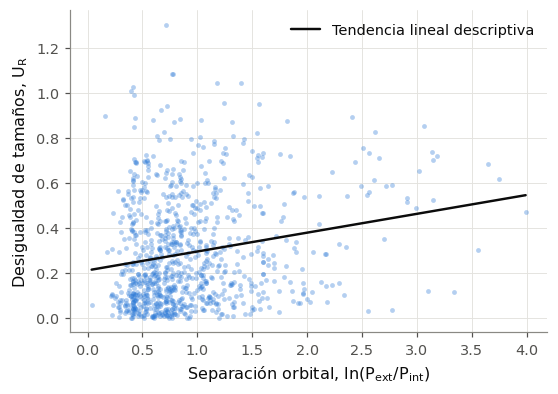

In [4]:
fig, ax = plt.subplots(figsize=(5.6, 3.8))
ax.scatter(pares["log_period_ratio"], pares["abs_log_radius_ratio"], s=10, color=COLOR_UNICO, alpha=0.35, linewidths=0)
pendiente, ordenada = np.polyfit(pares["log_period_ratio"], pares["abs_log_radius_ratio"], 1)
x = np.array([pares["log_period_ratio"].min(), pares["log_period_ratio"].max()])
ax.plot(x, ordenada + pendiente * x, color=TINTA, linewidth=1.6, label="Tendencia lineal descriptiva")
ax.set_xlabel(r"Separación orbital, $\ln(P_{\rm ext}/P_{\rm int})$")
ax.set_ylabel(r"Desigualdad de tamaños, $U_R$")
ax.legend(loc="upper right")
guardar_figura(fig, "C-F1", "separacion_orbital_y_desigualdad_de_tamanos",
               titulo="Desigualdad de tamaños de los pares de planetas adyacentes en función de su separación orbital.",
               seccion="Anexo", destino="anexo",
               nota=f"N = {len(pares)} pares; rho de Spearman = {s_pares['rho']:.3f} (IC 95 %: {s_pares['rho_IC95_inf']:.3f} a {s_pares['rho_IC95_sup']:.3f}).")
plt.show()

### Modelos lineales de $U_R$

- U1: separación + [Fe/H] + masa estelar + radio mediano del par + número de planetas.
- U2: separación + [Fe/H] + masa estelar + tipo de par (referencia: par mixto).
- U3: separación + [Fe/H] + separación × [Fe/H] + masa estelar + radio mediano del par.

Los errores están agrupados por estrella; en la nota de la tabla está el IC de la separación en U1 con errores clásicos.

In [5]:
pares["par_rocoso"] = (pares["pair_type"] == "par_rocoso").astype(float)
pares["par_volatil"] = (pares["pair_type"] == "par_volatil").astype(float)
pares["log_period_ratio_x_st_met"] = pares["log_period_ratio"] * pares["st_met"]
PREDICTORES_U = {
    "U1": ["log_period_ratio", "st_met", "st_mass", "pair_median_radius", "N_planetas"],
    "U2": ["log_period_ratio", "st_met", "st_mass", "par_rocoso", "par_volatil"],
    "U3": ["log_period_ratio", "st_met", "log_period_ratio_x_st_met", "st_mass", "pair_median_radius"],
}
y_U = pares["abs_log_radius_ratio"]
agrupados = {n: ajustar_lineal(y_U, matriz(pares, p), pares["hostname"], n) for n, p in PREDICTORES_U.items()}
clasicos = {n: ajustar_lineal(y_U, matriz(pares, p), nombre=n) for n, p in PREDICTORES_U.items()}

coeficientes = pd.concat([a.coeficientes() for a in agrupados.values()], ignore_index=True)
coeficientes.insert(2, "R2", coeficientes["modelo"].map({n: a.r2 for n, a in agrupados.items()}))
tabla_modelos = guardar_tabla(
    coeficientes, "C-T3", "modelos_lineales_desigualdad_de_tamanos",
    titulo="Pares adyacentes: coeficientes de los modelos lineales de la desigualdad de tamaños.",
    seccion="Anexo", destino="anexo",
    nota=("Errores estándar agrupados por estrella. Con errores clásicos, el IC 95 % de la separación orbital en U1 es "
          + "[{:.3f}, {:.3f}].".format(*clasicos["U1"].coeficientes(solo=["log_period_ratio"]).loc[0, ["IC95_inf", "IC95_sup"]])),
    encabezados={"par_rocoso": "Par rocoso", "par_volatil": "Par volátil"})
tabla_modelos

Tabla C-T3 guardada: tablas/C-T3_modelos_lineales_desigualdad_de_tamanos.csv


,modelo,predictor,R2,coeficiente,error_estandar,IC95_inf,IC95_sup,valor_p
0,U1,const,0.0597,0.2333,0.0486,0.1381,0.3285,1.570000e-06
1,U1,log_period_ratio,0.0597,0.0859,0.0150,0.0566,0.1153,9.430000e-09
2,U1,st_met,0.0597,0.1399,0.0474,0.0470,0.2328,3.170000e-03
3,U1,st_mass,0.0597,0.0567,0.0349,-0.0116,0.1250,1.040000e-01
4,U1,pair_median_radius,0.0597,-0.0352,0.0124,-0.0594,-0.0109,4.510000e-03
5,U1,N_planetas,0.0597,0.0012,0.0071,-0.0128,0.0152,8.630000e-01
6,U2,const,0.4638,0.4776,0.0285,0.4217,0.5334,4.010000e-63
7,U2,log_period_ratio,0.4638,0.0332,0.0103,0.0131,0.0533,1.220000e-03
8,U2,st_met,0.4638,0.1154,0.0374,0.0421,0.1886,2.020000e-03
9,U2,st_mass,0.4638,0.0149,0.0232,-0.0306,0.0604,5.210000e-01


### Robustez por submuestras

Se parte de una muestra más amplia (todos los planetas con $P<100$ d, sin restricción de radio) y se repite el análisis en siete submuestras.

In [6]:
amplia = df[df["hostname"].notna() & df["pl_rade"].notna() & df["pl_orbper"].notna()
            & df["st_met"].notna() & df["st_mass"].notna() & (df["pl_orbper"] < P_MAX_ARQUITECTURA)]
amplia = amplia[amplia.groupby("hostname")["pl_name"].transform("size") >= 2]
pares_amplios = construir_pares(amplia)

def analizar(nombre, d):
    s = spearman(d["log_period_ratio"], d["abs_log_radius_ratio"], n_boot=3000)
    predictores = [p for p in PREDICTORES_U["U1"] if d[p].nunique() > 1]     # sin predictores constantes
    m = ajustar_lineal(d["abs_log_radius_ratio"], matriz(d, predictores), d["hostname"])
    c = m.coeficientes(solo=["log_period_ratio"]).iloc[0]
    return {"submuestra": nombre, "N_pares": len(d), "N_sistemas": d["hostname"].nunique(), "rho": s["rho"],
            "rho_IC95_inf": s["rho_IC95_inf"], "rho_IC95_sup": s["rho_IC95_sup"],
            "pendiente": c["coeficiente"], "IC95_inf": c["IC95_inf"], "IC95_sup": c["IC95_sup"], "valor_p": c["valor_p"]}

submuestras = {
    "Muestra amplia (P < 100 d)": pares_amplios,
    "Ambos Rp > 1 R_Tierra": pares_amplios[(pares_amplios["R_in"] > 1) & (pares_amplios["R_out"] > 1)],
    "Ambos Rp < 4 R_Tierra": pares_amplios[(pares_amplios["R_in"] < 4) & (pares_amplios["R_out"] < 4)],
    "Solo tránsito": pares_amplios[pares_amplios["transit_only"]],
    "Sistemas de Kepler": pares_amplios[pares_amplios["kepler"]],
    "Sistemas con N = 2": pares_amplios[pares_amplios["N_planetas"] == 2],
    "Sistemas con N >= 3": pares_amplios[pares_amplios["N_planetas"] >= 3],
}
tabla_robustez = guardar_tabla(
    pd.DataFrame([analizar(n, d) for n, d in submuestras.items()]), "C-T4", "robustez_por_submuestras",
    titulo="Pares adyacentes: correlación de Spearman y pendiente controlada entre separación orbital y desigualdad de tamaños en siete submuestras.",
    seccion="Anexo", destino="anexo",
    nota="Pendiente de la separación orbital en el modelo U1, con errores agrupados por estrella. IC de rho por bootstrap (3000 remuestreos).",
    encabezados={"submuestra": "Submuestra", "pendiente": "Pendiente"})
tabla_robustez

Tabla C-T4 guardada: tablas/C-T4_robustez_por_submuestras.csv


,submuestra,N_pares,N_sistemas,rho,rho_IC95_inf,rho_IC95_sup,pendiente,IC95_inf,IC95_sup,valor_p
0,Muestra amplia (P < 100 d),1155,767,0.2212,0.1655,0.2779,0.1823,0.1400,0.2247,3.320000e-17
1,Ambos Rp > 1 R_Tierra,1036,704,0.2100,0.1517,0.2666,0.1483,0.1053,0.1913,1.410000e-11
2,Ambos Rp < 4 R_Tierra,980,658,0.1874,0.1235,0.2443,0.1422,0.1033,0.1812,8.010000e-13
3,Solo tránsito,797,539,0.2142,0.1457,0.2811,0.1570,0.1067,0.2073,9.540000e-10
4,Sistemas de Kepler,728,474,0.1770,0.1076,0.2466,0.1532,0.0947,0.2118,2.900000e-07
5,Sistemas con N = 2,505,505,0.2171,0.1283,0.3021,0.1559,0.1092,0.2025,5.750000e-11
6,Sistemas con N >= 3,650,262,0.2015,0.1249,0.2750,0.2553,0.1765,0.3342,2.220000e-10


## 3. Tipo de par respecto al valle de radios

In [7]:
globales, posthoc = [], None
for variable in ["abs_log_radius_ratio", "log_period_ratio", "st_met", "st_mass"]:
    tabla_global, tabla_pares_tipo = kruskal_posthoc(pares, "pair_type", variable, TIPOS)
    globales.append(tabla_global.drop(columns="grupo"))
    if variable == "abs_log_radius_ratio":
        posthoc = tabla_pares_tipo
texto_posthoc = "; ".join(f"{ETIQUETA_TIPO[f.grupo_0].lower()} vs {ETIQUETA_TIPO[f.grupo_1].lower()}: p de Holm = {f.valor_p_holm:.2g}"
                          for f in posthoc.itertuples())
tabla_tipo = guardar_tabla(
    pd.concat(globales, ignore_index=True), "C-T5", "kruskal_por_tipo_de_par",
    titulo="Pares adyacentes: prueba de Kruskal-Wallis entre pares rocosos, mixtos y volátiles.",
    seccion="Anexo", destino="anexo",
    nota="Comparaciones por pares de la desigualdad de tamaños: " + texto_posthoc + ".",
    encabezados={"k_grupos": "Grupos", "epsilon_cuadrado": r"$\epsilon^2$"})
tabla_tipo

Tabla C-T5 guardada: tablas/C-T5_kruskal_por_tipo_de_par.csv


,variable,N,k_grupos,H,valor_p,epsilon_cuadrado
0,abs_log_radius_ratio,898,3,380.6944,2.150000e-83,0.4244
1,log_period_ratio,898,3,30.9416,1.910000e-07,0.0345
2,st_met,898,3,12.0952,2.360000e-03,0.0135
3,st_mass,898,3,22.6491,1.210000e-05,0.0252


Figura C-F2 guardada: figuras/C-F2_desigualdad_de_tamanos_por_tipo_de_par.png y .pdf


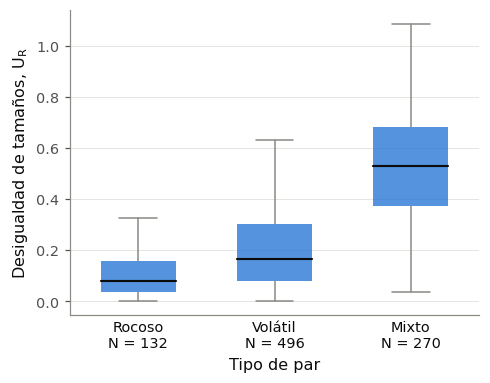

In [8]:
orden = ["par_rocoso", "par_volatil", "par_mixto"]
fig, ax = plt.subplots(figsize=(4.8, 3.6))
cajas(ax, [pares.loc[pares["pair_type"] == t, "abs_log_radius_ratio"] for t in orden],
              [f"{ETIQUETA_TIPO[t]}\nN = {int((pares['pair_type'] == t).sum())}" for t in orden],
              [COLOR_UNICO] * 3)
ax.set_ylabel(r"Desigualdad de tamaños, $U_R$")
ax.set_xlabel("Tipo de par")
ax.tick_params(axis="x", length=0, labelcolor=TINTA)
guardar_figura(fig, "C-F2", "desigualdad_de_tamanos_por_tipo_de_par",
               titulo="Desigualdad de tamaños de los pares adyacentes según el tipo de par respecto al límite de 1.6 R_Tierra.",
               seccion="Anexo", destino="anexo")
plt.show()

## 4. Ordenamiento de tamaños

Fracción de pares en que el planeta exterior es el mayor, global y por terciles, con intervalos de Wilson.

In [9]:
pares["tercil_separacion"] = pd.qcut(pares["log_period_ratio"], 3, labels=["T1 (baja)", "T2", "T3 (alta)"])
pares["tercil_st_met"] = pd.qcut(pares["st_met"], 3, labels=["T1 (baja)", "T2", "T3 (alta)"])
pares["tercil_st_mass"] = pd.qcut(pares["st_mass"], 3, labels=["T1 (baja)", "T2", "T3 (alta)"])
pares["todos"] = "Todos los pares"
partes = []
for agrupacion in ["todos", "tercil_separacion", "tercil_st_met", "tercil_st_mass", "pair_type"]:
    t = fraccion_por_grupo(pares, agrupacion, "outer_larger").rename(columns={agrupacion: "grupo", "N_positivos": "N_exterior_mayor"})
    t["grupo"] = t["grupo"].astype(str)
    t.insert(0, "agrupacion", agrupacion)
    partes.append(t)
ordenamiento = pd.concat(partes, ignore_index=True)
modelo_orden = ajustar_logit(pares["outer_larger"], matriz(pares, ["st_met", "st_mass", "log_period_ratio"]),
                                     pares["hostname"], "ordenamiento")
texto_or = "; ".join(f"{f.predictor}: {f.OR:.2f} [{f.OR_IC95_inf:.2f}, {f.OR_IC95_sup:.2f}]"
                     for f in modelo_orden.coeficientes(solo=["st_met", "st_mass", "log_period_ratio"]).itertuples())
tabla_ordenamiento = guardar_tabla(
    ordenamiento, "C-T6", "ordenamiento_de_tamanos",
    titulo="Pares adyacentes: fracción de pares en que el planeta exterior es el mayor, con intervalo de Wilson al 95 %.",
    seccion="Anexo", destino="anexo", decimales=3,
    nota="Razones de momios del modelo logístico outer_larger ~ st_met + st_mass + log_period_ratio (IC 95 %, errores agrupados por estrella): " + texto_or + ".",
    encabezados={"agrupacion": "Agrupación", "grupo": "Grupo", "N_exterior_mayor": "Exterior mayor"})
tabla_ordenamiento

Tabla C-T6 guardada: tablas/C-T6_ordenamiento_de_tamanos.csv


,agrupacion,grupo,N,N_exterior_mayor,fraccion,IC95_inf,IC95_sup
0,todos,Todos los pares,898,618,0.688,0.657,0.718
1,tercil_separacion,T1 (baja),300,178,0.593,0.537,0.647
2,tercil_separacion,T2,299,205,0.686,0.631,0.736
3,tercil_separacion,T3 (alta),299,235,0.786,0.736,0.829
4,tercil_st_met,T1 (baja),310,204,0.658,0.604,0.709
5,tercil_st_met,T2,291,206,0.708,0.653,0.757
6,tercil_st_met,T3 (alta),297,208,0.700,0.646,0.750
7,tercil_st_mass,T1 (baja),303,199,0.657,0.602,0.708
8,tercil_st_mass,T2,296,206,0.696,0.641,0.746
9,tercil_st_mass,T3 (alta),299,213,0.712,0.659,0.761


Figura C-F3 guardada: figuras/C-F3_ordenamiento_de_tamanos_por_separacion.png y .pdf


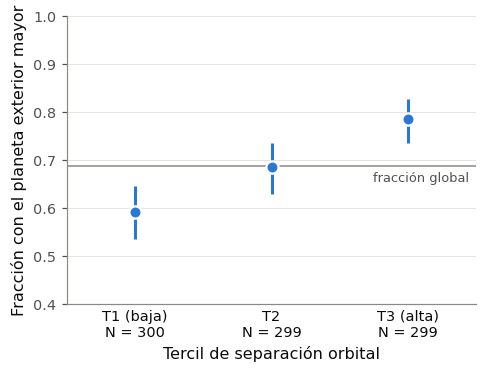

In [10]:
t = ordenamiento[ordenamiento["agrupacion"] == "tercil_separacion"]
fig, ax = plt.subplots(figsize=(4.8, 3.4))
x = np.arange(len(t))
linea_referencia(ax, pares["outer_larger"].mean(), eje="y")
ax.vlines(x, t["IC95_inf"], t["IC95_sup"], color=COLOR_UNICO, linewidth=2)
ax.plot(x, t["fraccion"], "o", color=COLOR_UNICO, markersize=8, markeredgecolor="white", markeredgewidth=1.5)
ax.text(len(t) - 0.55, pares["outer_larger"].mean() - 0.012, "fracción global", ha="right", va="top", fontsize=8.5, color=TINTA_SECUNDARIA)
ax.set_xticks(x)
ax.set_xticklabels([f"{g}\nN = {n}" for g, n in zip(t["grupo"], t["N"])])
ax.tick_params(axis="x", length=0, labelcolor=TINTA)
ax.set_xlim(-0.5, len(t) - 0.5)
ax.set_ylim(0.4, 1.0)
ax.set_xlabel("Tercil de separación orbital")
ax.set_ylabel("Fracción con el planeta exterior mayor")
ax.grid(axis="x", visible=False)
guardar_figura(fig, "C-F3", "ordenamiento_de_tamanos_por_separacion",
               titulo="Fracción de pares adyacentes en que el planeta exterior es el mayor, por tercil de separación orbital. Las barras son intervalos de Wilson al 95 %.",
               seccion="Anexo", destino="anexo")
plt.show()

## Lectura de los resultados

- Los pares más separados tienden a ser más desiguales en tamaño; la asociación es débil pero se mantiene al controlar por la estrella y el sistema, con errores agrupados y en todas las submuestras.
- El tipo de par explica la mayor parte de la desigualdad (los pares mixtos, que cruzan el límite de $1.6\,R_\oplus$, son los más desiguales), sin eliminar el efecto de la separación.
- La metalicidad no modifica la relación entre separación y desigualdad (interacción en U3).
- El planeta exterior tiende a ser el mayor, más aún en los pares más separados.